# Rețele neuronale și deep learning — Cursul 7: Atenția și transformerele
Prof. dr. Daniel Traian Pele — Academia de Studii Economice din București (ASE); Academia Română, Institutul de Prognoză Economică (IPE)

[Deschide în Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L7_notebook_ro.ipynb)

Acest notebook reproduce cifrele și graficele cursului pe datele reale din `../data/clean` (vezi `../data/SOURCES.md`). Numerele secțiunilor (§) corespund indicațiilor *Exercițiu practic* de pe slide-uri.

In [1]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 Datele și tokenii
Tweet-uri financiare (negative, pozitive, neutre); setul de validare publicat este setul nostru de test. Lungimea textelor în tokeni WordPiece.

In [3]:
import math, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification
tw = pd.read_csv(DATA + 'twitter_fin_sentiment.csv')            # 0 bearish, 1 bullish, 2 neutral
tr_all, te = tw[tw.split == 'train'].reset_index(drop=True), tw[tw.split == 'valid'].reset_index(drop=True)
tr, va = train_test_split(tr_all, test_size=0.10, stratify=tr_all.label, random_state=SEED)
tr, va = tr.reset_index(drop=True), va.reset_index(drop=True)
ytr, yva, yte = tr.label.values, va.label.values, te.label.values
tok = AutoTokenizer.from_pretrained('ProsusAI/finbert')
def enc(texts, n=64):
    e = tok(list(texts), padding='max_length', truncation=True, max_length=n, return_tensors='pt')
    return e['input_ids'], e['attention_mask']
Itr, Mtr = enc(tr.text); Iva, Mva = enc(va.text); Ite, Mte = enc(te.text)
print('train', len(tr), 'validation', len(va), 'test', len(te), ' vocabulary', tok.vocab_size)

train 8588 validation 955 test 2388  vocabulary 30522


In [4]:
print(tok.tokenize(te.text[0]))
sp = pd.read_csv(DATA + 'ecb_speeches_2022plus.csv')
len_tw = np.array([len(x) for x in tok(list(tw.text))['input_ids']])
len_sp = np.array([len(x) for x in tok(list(sp.contents.astype(str)))['input_ids']])
print('median tokens: tweets', int(np.median(len_tw)), ' ECB speeches', int(np.median(len_sp)), ' speeches > 512:', round(100 * np.mean(len_sp > 512), 1), '%')

['$', 'ally', '-', 'ally', 'financial', 'pulls', 'outlook', 'https', ':', '/', '/', 't', '.', 'co', '/', 'g', '##9', '##zd', '##i', '##1', '##boy', '##5']


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (5057 > 512). Running this sequence through the model will result in indexing errors


median tokens: tweets 25  ECB speeches 3338  speeches > 512: 98.8 %


## §2 Atenția cu produs scalar scalat, calculată manual
$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}(QK^\top/\sqrt{d_k})V$, verificată pe primul strat al FinBERT, pentru un tweet real.

In [5]:
fb = AutoModelForSequenceClassification.from_pretrained('ProsusAI/finbert', attn_implementation='eager').eval()
e1 = tok(te.text[0], return_tensors='pt')
with torch.no_grad():
    out = fb(**e1, output_attentions=True, output_hidden_states=True)
X0 = out.hidden_states[0][0]                       # input of layer 1: n x 768
at = fb.bert.encoder.layer[0].attention.self
Q, K = at.query(X0), at.key(X0)                    # all 12 heads, 64 dimensions each
h = 0; q, k = Q[:, 64*h:64*(h+1)], K[:, 64*h:64*(h+1)]
A = torch.softmax(q @ k.T / math.sqrt(64), dim=-1)
print('max difference with the model:', float((A - out.attentions[0][0, h]).abs().max()))
print('row sums:', A.sum(1)[:3].tolist())
raw = (q @ k.T).flatten(); print('sd of raw scores', round(float(raw.std()), 2), ' scaled', round(float((raw / 8).std()), 2))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

max difference with the model: 0.0
row sums: [1.0000001192092896, 0.9999998807907104, 1.0]
sd of raw scores 5.25  scaled 0.66


## §3 Un transformer mic, de la zero
Reprezentările tokenilor și pozițiile sinusoidale, 2 blocuri (4 capete, $d=64$), media pe tokeni, 3 clase. **Exercițiu practic:** puneți `pos=False`.

In [6]:
class TinyTransformer(nn.Module):
    def __init__(self, vocab, d=64, heads=4, layers=2, ff=128, drop=0.1, pos=True, n=64):
        super().__init__()
        self.emb, self.pos = nn.Embedding(vocab, d, padding_idx=0), pos
        p = torch.arange(n)[:, None]; div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe = torch.zeros(n, d); pe[:, 0::2], pe[:, 1::2] = torch.sin(p * div), torch.cos(p * div); self.register_buffer('pe', pe)
        blk = nn.TransformerEncoderLayer(d, heads, ff, drop, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(blk, layers, enable_nested_tensor=False); self.drop = nn.Dropout(drop); self.head = nn.Linear(d, 3)
    def forward(self, ids, mask):
        h = self.emb(ids) * math.sqrt(self.emb.embedding_dim) + (self.pe[:ids.shape[1]] if self.pos else 0)
        h = self.enc(self.drop(h), src_key_padding_mask=(mask == 0)); m = mask.unsqueeze(-1).float()
        return self.head((h * m).sum(1) / m.sum(1))

def train_tiny(pos=True, seed=1, epochs=20, patience=4):
    torch.manual_seed(seed); model = TinyTransformer(tok.vocab_size, pos=pos).to(DEVICE)
    w = torch.tensor(len(ytr) / (3 * np.bincount(ytr)), dtype=torch.float32, device=DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.01); best, state, wait = -1, None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(ytr))
        for b in range(0, len(perm), 64):
            j = perm[b:b + 64]; loss = F.cross_entropy(model(Itr[j].to(DEVICE), Mtr[j].to(DEVICE)), torch.tensor(ytr)[j].to(DEVICE), weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            fv = f1_score(yva, model(Iva.to(DEVICE), Mva.to(DEVICE)).argmax(1).cpu(), average='macro')
        print(f'epoch {ep + 1}: validation macro-F1 {fv:.3f}')
        if fv > best: best, wait, state = fv, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); model.eval()
    with torch.no_grad():
        return model(Ite.to(DEVICE), Mte.to(DEVICE)).argmax(1).cpu().numpy()

pred_tiny = train_tiny()
print('small transformer, test macro-F1:', round(100 * f1_score(yte, pred_tiny, average='macro'), 1))

epoch 1: validation macro-F1 0.427


epoch 2: validation macro-F1 0.449


epoch 3: validation macro-F1 0.477


epoch 4: validation macro-F1 0.571


epoch 5: validation macro-F1 0.530


epoch 6: validation macro-F1 0.607


... (10 outputs left out)

epoch 17: validation macro-F1 0.676


epoch 18: validation macro-F1 0.692


epoch 19: validation macro-F1 0.706


epoch 20: validation macro-F1 0.688
small transformer, test macro-F1: 69.4


## §4 Atenția din interiorul FinBERT
Atenția din ultimul strat, mediată pe cele 12 capete, pentru un tweet de test; entropia atenției pe straturi.

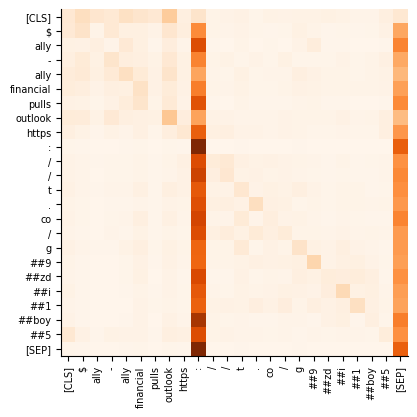

normalised entropy by layer: [0.76 0.54 0.45 0.57 0.48 0.39 0.4  0.37 0.48 0.51 0.56 0.55]


In [7]:
toks = tok.convert_ids_to_tokens(e1['input_ids'][0])
A12 = out.attentions[-1][0].mean(0).numpy()
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(A12, cmap='Oranges')
ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=7)
ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=7); plt.show()
ent = []
with torch.no_grad():
    o = fb(input_ids=Ite[:100], attention_mask=Mte[:100], output_attentions=True)
for A in o.attentions:
    vals = []
    for r in range(100):
        n = int(Mte[r].sum()); a = A[r, :, :n, :n].clamp_min(1e-12)
        vals.append(float((-(a * a.log()).sum(-1) / math.log(n)).mean()))
    ent.append(np.mean(vals))
print('normalised entropy by layer:', np.round(ent, 2))

## §5 Modele de referință, FinBERT fără antrenare, FinBERT înghețat și ajustarea fină
Etichetele FinBERT (positive, negative, neutral) devin (pozitiv, negativ, neutru). Ajustarea fină: o epocă aici, trei în slide-uri.

In [8]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(tr.text)
p_tfidf = LogisticRegression(C=10, max_iter=3000, class_weight='balanced').fit(Xtr, ytr).predict(vec.transform(te.text))
fb = fb.to(DEVICE); fin2our = {0: 1, 1: 0, 2: 2}
def run(model, I, M, hidden=False):
    L, H = [], []
    with torch.no_grad():
        for b in range(0, len(I), 256):
            o = model(input_ids=I[b:b+256].to(DEVICE), attention_mask=M[b:b+256].to(DEVICE), output_hidden_states=hidden)
            L.append(o.logits.float().cpu())
            if hidden:
                m = M[b:b+256].to(DEVICE).unsqueeze(-1).float(); H.append(((o.hidden_states[-1] * m).sum(1) / m.sum(1)).float().cpu())
    return torch.cat(L), (torch.cat(H).numpy() if hidden else None)
lg, hte = run(fb, Ite, Mte, hidden=True); _, htr = run(fb, Itr, Mtr, hidden=True)
p_zs = np.array([fin2our[int(i)] for i in lg.argmax(1)])
p_probe = LogisticRegression(C=0.1, max_iter=5000, class_weight='balanced').fit(htr, ytr).predict(hte)
for name, p in [('TF-IDF', p_tfidf), ('small transformer', pred_tiny), ('FinBERT zero-shot', p_zs), ('FinBERT frozen + logistic', p_probe)]:
    print(f'{name:26s} macro-F1 {100 * f1_score(yte, p, average="macro"):.1f}  accuracy {100 * accuracy_score(yte, p):.1f}')

TF-IDF                     macro-F1 75.5  accuracy 81.8
small transformer          macro-F1 69.4  accuracy 76.5
FinBERT zero-shot          macro-F1 66.9  accuracy 72.6
FinBERT frozen + logistic  macro-F1 75.1  accuracy 80.1


In [9]:
# fine-tuning: all weights, AdamW 2e-5, one epoch, batch 32
our2fin = {0: 1, 1: 0, 2: 2}; yfin = torch.tensor([our2fin[int(v)] for v in ytr])
torch.manual_seed(1); fb.train(); opt = torch.optim.AdamW(fb.parameters(), lr=2e-5, weight_decay=0.01)
perm = torch.randperm(len(ytr))
for b in range(0, len(perm), 32):
    j = perm[b:b+32]; loss = F.cross_entropy(fb(input_ids=Itr[j].to(DEVICE), attention_mask=Mtr[j].to(DEVICE)).logits, yfin[j].to(DEVICE))
    opt.zero_grad(); loss.backward(); opt.step()
fb.eval(); lg, _ = run(fb, Ite, Mte)
p_ft = np.array([fin2our[int(i)] for i in lg.argmax(1)])
print('FinBERT fine-tuned (1 epoch) macro-F1', round(100 * f1_score(yte, p_ft, average='macro'), 1))
print(confusion_matrix(yte, p_ft))

FinBERT fine-tuned (1 epoch) macro-F1 83.1
[[ 272   20   55]
 [  13  384   78]
 [  72   71 1423]]


## §6 De cîte date etichetate este nevoie?
TF-IDF și FinBERT înghețat, antrenate pe 5 %, 25 % și 100 % dintre tweet-urile de antrenare.

In [10]:
for fr in [0.05, 0.25, 1.0]:
    idx = np.arange(len(ytr)) if fr == 1 else train_test_split(np.arange(len(ytr)), train_size=fr, stratify=ytr, random_state=1)[0]
    v2 = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True); xa = v2.fit_transform(tr.text.iloc[idx])
    f_t = f1_score(yte, LogisticRegression(C=10, max_iter=3000, class_weight='balanced').fit(xa, ytr[idx]).predict(v2.transform(te.text)), average='macro')
    f_p = f1_score(yte, LogisticRegression(C=0.1, max_iter=5000, class_weight='balanced').fit(htr[idx], ytr[idx]).predict(hte), average='macro')
    print(f'{len(idx):5d} tweets: TF-IDF {100 * f_t:.1f}   frozen FinBERT {100 * f_p:.1f}')

  429 tweets: TF-IDF 51.5   frozen FinBERT 70.0


 2147 tweets: TF-IDF 65.2   frozen FinBERT 72.5


 8588 tweets: TF-IDF 75.5   frozen FinBERT 75.1
